In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_parquet("../data/processed/cicids2017_clean.parquet")
print(df.shape)
df.head()

(2497980, 75)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Idle Mean,Idle Std,Idle Max,Idle Min,Label,day,day_order,row_in_file,family,is_attack
0,54865,3.0,2.0,0.0,12.0,0.0,6.0,6.0,6.0,0.0,...,0.0,0.0,0.0,0.0,BENIGN,Friday-PM-DDoS,7,0,Normal,0
1,55054,109.0,1.0,1.0,6.0,6.0,6.0,6.0,6.0,0.0,...,0.0,0.0,0.0,0.0,BENIGN,Friday-PM-DDoS,7,1,Normal,0
2,55055,52.0,1.0,1.0,6.0,6.0,6.0,6.0,6.0,0.0,...,0.0,0.0,0.0,0.0,BENIGN,Friday-PM-DDoS,7,2,Normal,0
3,46236,34.0,1.0,1.0,6.0,6.0,6.0,6.0,6.0,0.0,...,0.0,0.0,0.0,0.0,BENIGN,Friday-PM-DDoS,7,3,Normal,0
4,54863,3.0,2.0,0.0,12.0,0.0,6.0,6.0,6.0,0.0,...,0.0,0.0,0.0,0.0,BENIGN,Friday-PM-DDoS,7,4,Normal,0


family
Normal          82.957
DoS/DDoS        12.881
PortScan         3.631
Brute Force      0.366
Web Attack       0.086
Botnet           0.078
Infiltration     0.001
Name: proportion, dtype: float64


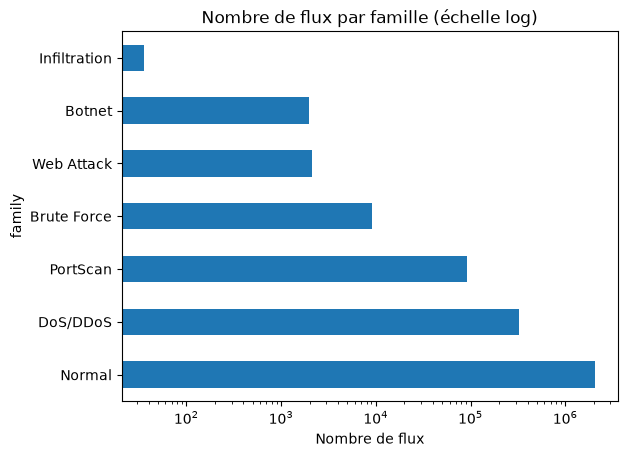

In [2]:
print(df["family"].value_counts(normalize=True).mul(100).round(3))

df["family"].value_counts().plot(kind="barh", logx=True)
plt.title("Nombre de flux par famille (échelle log)")
plt.xlabel("Nombre de flux")
plt.show()

In [3]:
pd.crosstab(df["day"], df["family"])

family,Botnet,Brute Force,DoS/DDoS,Infiltration,Normal,PortScan,Web Attack
day,,,,,,,
Friday-AM,1948,0,0,0,178136,0,0
Friday-PM-DDoS,0,0,128014,0,95068,0,0
Friday-PM-PortScan,0,0,0,0,121560,90694,0
Monday,0,0,0,0,492605,0,0
Thursday-AM,0,0,0,0,152314,0,2143
Thursday-PM,0,0,0,36,242404,0,0
Tuesday,0,9150,0,0,397317,0,0
Wednesday,0,0,193741,0,392850,0,0


In [4]:
df[["Flow Duration", "Total Fwd Packets", "Flow Bytes/s", "Flow Packets/s"]].describe().round(1)

,Flow Duration,Total Fwd Packets,Flow Bytes/s,Flow Packets/s
count,2497980.0,2497980.0,2.497980e+06,2497980.0
mean,16737821.0,10.4,1.412812e+06,47463.6
std,35355012.0,798.0,2.668788e+07,203360.1
min,-13.0,1.0,-2.610000e+08,-2000000.0
25%,212.0,2.0,1.192000e+02,2.0
50%,51822.0,2.0,3.614700e+03,66.5
75%,5387463.8,6.0,9.677420e+04,17391.3
max,120000000.0,219759.0,2.071000e+09,4000000.0


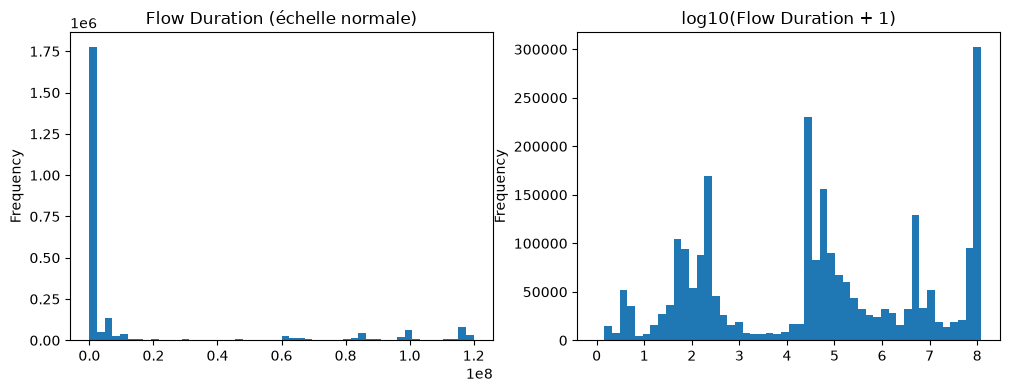

In [5]:
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df["Flow Duration"].plot(kind="hist", bins=50, ax=axes[0])
axes[0].set_title("Flow Duration (échelle normale)")

np.log10(df["Flow Duration"].clip(lower=0) + 1).plot(kind="hist", bins=50, ax=axes[1])
axes[1].set_title("log10(Flow Duration + 1)")

plt.show()

In [6]:
meta = ["Label", "day", "day_order", "row_in_file", "family", "is_attack"]
X = df.drop(columns=meta)

skew = X.skew().sort_values(ascending=False)
print(f"{(skew.abs() > 2).sum()} variables très asymétriques sur {X.shape[1]}")
skew.head(10).round(0)

64 variables très asymétriques sur 69


Total Length of Fwd Packets    757.0
Subflow Fwd Bytes              755.0
act_data_pkt_fwd               267.0
Total Backward Packets         230.0
Subflow Bwd Packets            230.0
Total Fwd Packets              230.0
Subflow Fwd Packets            230.0
Subflow Bwd Bytes              230.0
Total Length of Bwd Packets    230.0
CWE Flag Count                 177.0
dtype: float64

In [7]:
negatives = X.columns[X.min() < 0]
print(f"{len(negatives)} colonnes contiennent des valeurs négatives :")
X[negatives].min()

12 colonnes contiennent des valeurs négatives :


Flow Duration             -1.300000e+01
Flow Bytes/s              -2.610000e+08
Flow Packets/s            -2.000000e+06
Flow IAT Mean             -1.300000e+01
Flow IAT Max              -1.300000e+01
Flow IAT Min              -1.400000e+01
Fwd IAT Min               -1.200000e+01
Fwd Header Length         -3.221223e+10
Bwd Header Length         -1.073741e+09
Init_Win_bytes_forward    -1.000000e+00
Init_Win_bytes_backward   -1.000000e+00
min_seg_size_forward      -5.368707e+08
dtype: float32

In [8]:
df.groupby("family", observed=True)[
    ["Flow Duration", "Flow Packets/s", "Destination Port"]
].median()

,Flow Duration,Flow Packets/s,Destination Port
family,,,
Botnet,71035.5,100.962025,8080.0
Brute Force,9114177.0,4.064360,21.0
DoS/DDoS,73711984.0,0.178595,80.0
Infiltration,93188868.0,0.997978,444.0
Normal,46287.0,84.496925,80.0
PortScan,50.0,40000.000000,3546.0
Web Attack,5487328.0,0.740812,80.0


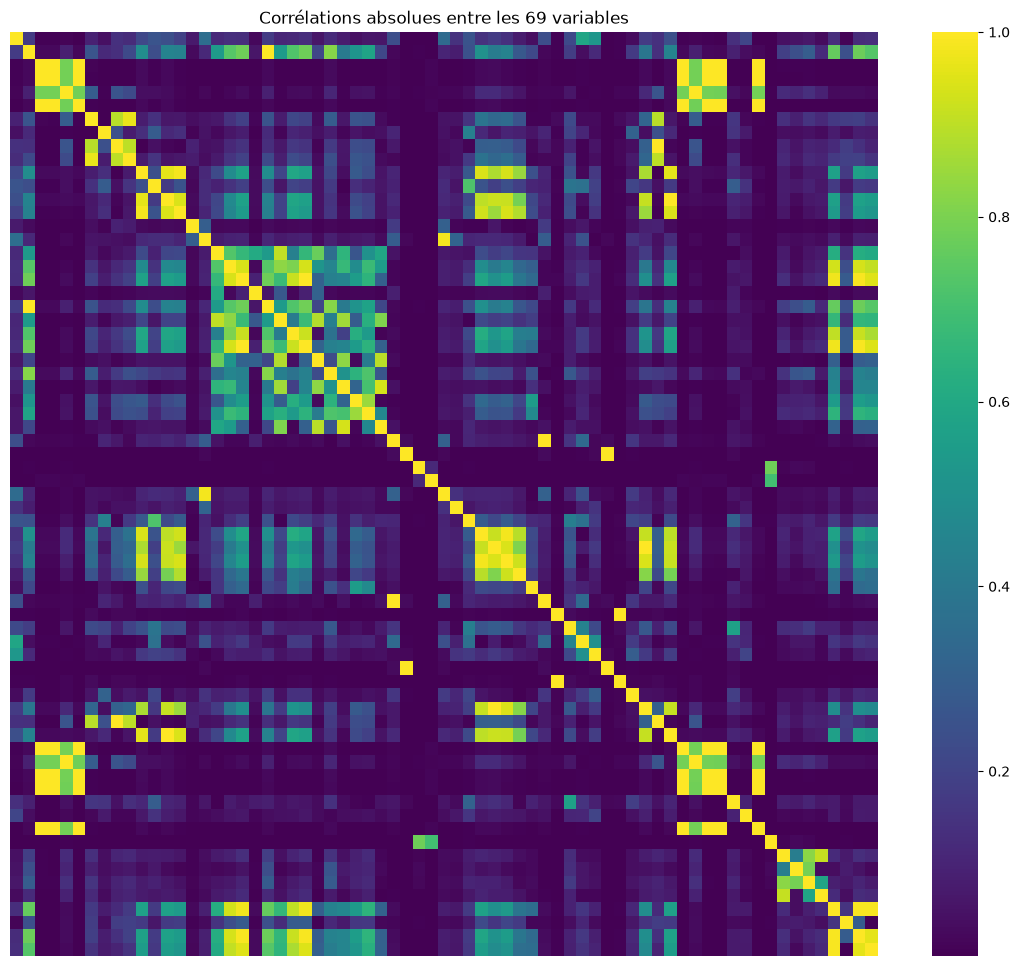

44 paires de variables corrélées à plus de 0,95


Bwd Packet Length Mean       Avg Bwd Segment Size    1.0
Total Length of Fwd Packets  Subflow Fwd Bytes       1.0
Fwd PSH Flags                SYN Flag Count          1.0
RST Flag Count               ECE Flag Count          1.0
Total Fwd Packets            Subflow Fwd Packets     1.0
Fwd URG Flags                CWE Flag Count          1.0
Total Backward Packets       Subflow Bwd Packets     1.0
Fwd Packet Length Mean       Avg Fwd Segment Size    1.0
Total Length of Bwd Packets  Subflow Bwd Bytes       1.0
Subflow Fwd Packets          Subflow Bwd Packets     1.0
dtype: float64

In [9]:
import seaborn as sns

sample = X.sample(200_000, random_state=42)
corr = sample.corr().abs()

plt.figure(figsize=(14, 12))
sns.heatmap(corr, cmap="viridis", xticklabels=False, yticklabels=False)
plt.title("Corrélations absolues entre les 69 variables")
plt.show()

upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = upper.stack().sort_values(ascending=False)
print(f"{(pairs > 0.95).sum()} paires de variables corrélées à plus de 0,95")
pairs.head(10).round(3)